<a href="https://colab.research.google.com/github/nhuvtq87/AAI2025/blob/2026fall/Inventory_Replenishment_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inventory Replenishment Agent

### Learning goals
- Load and prep supply chain data (sales / stock / lead times)
- Build a simple demand forecaster (**EWMA**, with a **naive** benchmark)
- Implement an **agent loop** that recommends purchase orders from projected stockouts, service level and lead time
- Simulate outcomes and evaluate **stockouts, fill rate and total cost**

### How the agent works (one loop per SKU per day)
| Step | What happens | Code |
|---|---|---|
| **Observe** | on-hand, on-order pipeline, today's sales | `Obs` |
| **Forecast** | EWMA daily demand + forecast-error σ | `tool_forecast` |
| **Plan** | safety stock & reorder point over lead time + review period; project on-hand day by day | `tool_safety_stock`, `tool_project` |
| **Decide** | ORDER (respecting MOQ) or WAIT (save holding cost) — with a written rationale | `ReplenishmentAgent.decide` |
| **Act** | PO goes into the pipeline, lands after `lead_time_days` | `InventorySim.place_order` |

### Modeling assumptions
- **Timing:** POs arrive at the *start* of a day → customers buy → agent reviews at *end* of day.
- **Lost sales** (unmet demand is gone, not backordered) → fill rate = units sold ÷ units demanded.
- **Costs:** holding = ending on-hand × `holding_cost_per_day`; stockout = lost units × `stockout_cost`; order cost = `ORDER_COST_FIXED` per PO (0 by default, per the brief).
- The first `WARMUP_DAYS` of sales seed the forecaster; the simulation runs on the rest.

In [1]:
import os, math
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# ---------------- Config (tweak here) ----------------
ALPHA            = 0.3      # EWMA smoothing (higher = reacts faster to recent days)
SIGMA_WINDOW     = 28       # trailing days used to measure forecast error
WARMUP_DAYS      = 14       # history used to seed the forecaster before simulating
REVIEW_PERIOD    = 1        # agent reviews every R days (1 = daily)
ORDER_COST_FIXED = 0.0      # $ per PO (set e.g. 25 to see the agent batch orders)

## 1. Data — load the 3 CSVs
Set `DATA_DIR` to the folder with `sales.csv`, `inventory.csv` and `params.csv`.

In [2]:
import os
import pandas as pd

# ---------------- Data file paths ----------------
DATA_DIR = '/content'   # folder holding the 3 CSVs, e.g. '/content' on Colab

SALES_PATH     = os.path.join(DATA_DIR, 'sales.csv')
INVENTORY_PATH = os.path.join(DATA_DIR, 'inventory.csv')
PARAMS_PATH    = os.path.join(DATA_DIR, 'params.csv')

missing = [f for f in (SALES_PATH, INVENTORY_PATH, PARAMS_PATH) if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Missing data file(s): {missing}. Put the CSVs in DATA_DIR or update the path above.')

sales_raw = pd.read_csv(SALES_PATH, parse_dates=['date'])
inventory = pd.read_csv(INVENTORY_PATH).set_index('sku')
params_df = pd.read_csv(PARAMS_PATH).set_index('sku')

# Quick schema check so a wrong file fails loudly here, not halfway through the sim
expected = {
    'sales.csv':     (sales_raw, {'date', 'sku', 'qty_sold'}),
    'inventory.csv': (inventory.reset_index(), {'sku', 'opening_stock'}),
    'params.csv':    (params_df.reset_index(), {'sku', 'unit_cost', 'holding_cost_per_day', 'stockout_cost',
                                                'lead_time_days', 'min_order_qty', 'service_level'}),
}
for name, (df, cols) in expected.items():
    gap = cols - set(df.columns)
    assert not gap, f'{name} is missing columns: {gap}'

print(f'Loaded {len(sales_raw)} sales rows | SKUs: {sorted(sales_raw.sku.unique())}')
print(f'Date range: {sales_raw.date.min().date()} -> {sales_raw.date.max().date()}\n')
print(inventory, '\n')
print(params_df)

Loaded 270 sales rows | SKUs: ['SKU-A100', 'SKU-B200', 'SKU-C300']
Date range: 2026-07-29 -> 2026-10-26

          opening_stock
sku                    
SKU-A100            334
SKU-B200            114
SKU-C300            524 

          unit_cost  holding_cost_per_day  stockout_cost  lead_time_days  min_order_qty  service_level
sku                                                                                                   
SKU-A100      12.50                0.0086           6.25               5             50           0.95
SKU-B200      45.00                0.0308          22.50              10             20           0.90
SKU-C300       3.75                0.0026           1.88               3            100           0.98


### Task 1 — Aggregate demand per day per SKU
Sums duplicate rows and fills missing days with 0 so every SKU has a complete daily series.

90 days x 3 SKUs  (2026-07-29 -> 2026-10-26)


,mean,std,min,max
sku,,,,
SKU-A100,23.8,5.8,15.0,56.0
SKU-B200,8.1,3.1,2.0,18.0
SKU-C300,37.4,12.5,11.0,72.0


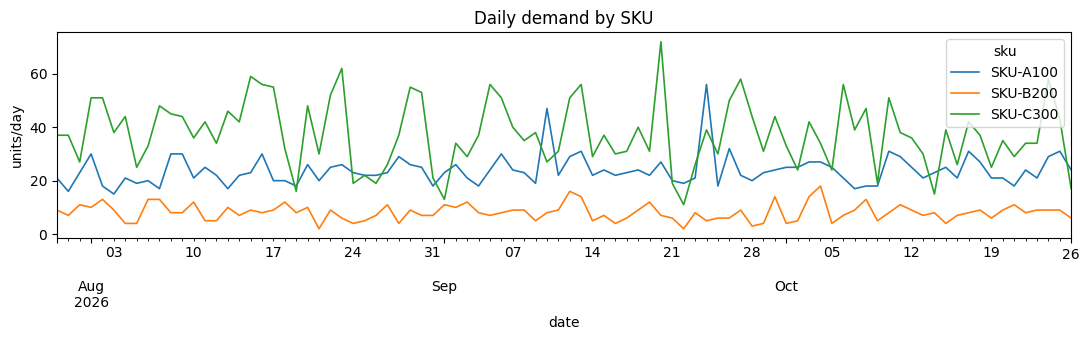

In [3]:
all_days = pd.date_range(sales_raw['date'].min(), sales_raw['date'].max(), freq='D')
demand = (sales_raw.groupby(['date','sku'])['qty_sold'].sum()
          .unstack('sku')
          .reindex(all_days, fill_value=0)
          .fillna(0).astype(int))
demand.index.name = 'date'
SKUS = list(demand.columns)

print(f'{len(demand)} days x {len(SKUS)} SKUs  ({demand.index[0].date()} -> {demand.index[-1].date()})')
display(demand.describe().round(1).T[['mean','std','min','max']])

ax = demand.plot(figsize=(11,3.5), lw=1.2)
ax.set_title('Daily demand by SKU'); ax.set_ylabel('units/day'); plt.tight_layout(); plt.show()

## 2. Demand forecast — EWMA (and naive benchmark)
At the end of day *t* the forecast for every future day is the EWMA level:

$\hat{d}_{t+1} = \alpha\, d_t + (1-\alpha)\, \hat{d}_t$

The **naive** forecaster just says tomorrow = today. Forecast error σ is the std of one-step-ahead errors over a trailing window — this feeds safety stock.

MAE          RMSE       
model      EWMA  Naive   EWMA  Naive
sku                                 
SKU-A100   4.22   5.33   6.55   8.77
SKU-B200   2.55   3.22   3.37   4.21
SKU-C300  11.58  13.72  14.41  17.20

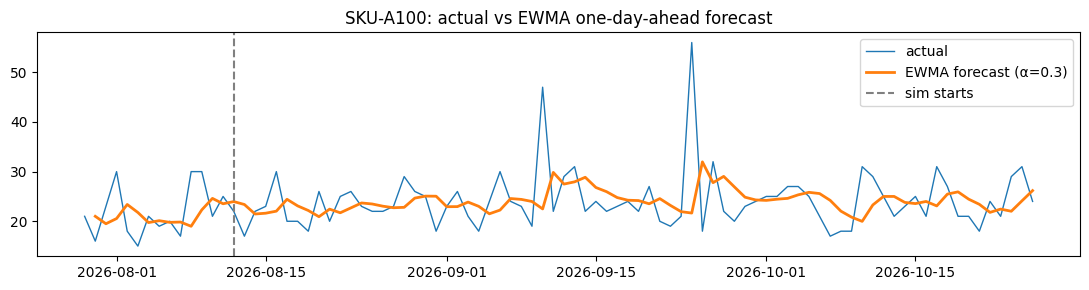

In [4]:
def ewma_forecaster(y: pd.Series, alpha=ALPHA) -> pd.Series:
    """Forecast level made at END of day t (uses data through t) -> forecast for t+1, t+2, ..."""
    return y.ewm(alpha=alpha, adjust=False).mean()

def naive_forecaster(y: pd.Series, **_) -> pd.Series:
    return y.astype(float)

FORECASTERS = {'EWMA': ewma_forecaster, 'Naive': naive_forecaster}

def forecast_table(y: pd.Series, forecaster, window=SIGMA_WINDOW):
    level = forecaster(y)
    err = y - level.shift(1)                                   # one-step-ahead error
    sigma = err.rolling(window, min_periods=7).std()
    return pd.DataFrame({'actual': y, 'forecast_next': level, 'err': err, 'sigma': sigma})

# Accuracy check on the post-warm-up period
rows = []
for sku in SKUS:
    for name, fc in FORECASTERS.items():
        t = forecast_table(demand[sku], fc).iloc[WARMUP_DAYS:]
        rows.append({'sku': sku, 'model': name, 'MAE': t['err'].abs().mean(),
                     'RMSE': np.sqrt((t['err']**2).mean()), 'bias': t['err'].mean()})
acc = pd.DataFrame(rows).pivot(index='sku', columns='model', values=['MAE','RMSE']).round(2)
display(acc)

sku0 = SKUS[0]
ft = forecast_table(demand[sku0], ewma_forecaster)
plt.figure(figsize=(11,3))
plt.plot(ft.index, ft['actual'], label='actual', lw=1)
plt.plot(ft.index, ft['forecast_next'].shift(1), label=f'EWMA forecast (α={ALPHA})', lw=2)
plt.axvline(demand.index[WARMUP_DAYS], ls='--', c='gray', label='sim starts')
plt.title(f'{sku0}: actual vs EWMA one-day-ahead forecast'); plt.legend(); plt.tight_layout(); plt.show()

## 3. Safety stock from forecast error & service level
The agent protects against demand over **P = lead time + review period** days:

- $z = \Phi^{-1}(\text{service\_level})$
- $SS = z \cdot \sigma \cdot \sqrt{P}$
- **Reorder point / order-up-to:** $ROP = \hat{d}\cdot P + SS$

Snapshot at the start of the simulation:

In [5]:
def tool_safety_stock(sigma, service_level, P):
    z = norm.ppf(service_level)
    return z, z * sigma * math.sqrt(P)

snap = []
start_day = demand.index[WARMUP_DAYS - 1]
for sku in SKUS:
    p = params_df.loc[sku]
    ft = forecast_table(demand[sku], ewma_forecaster)
    f, s = ft.loc[start_day, 'forecast_next'], ft.loc[start_day, 'sigma']
    P = int(p.lead_time_days) + REVIEW_PERIOD
    z, ss = tool_safety_stock(s, p.service_level, P)
    snap.append({'sku': sku, 'forecast/day': f, 'sigma': s, 'service_level': p.service_level, 'z': z,
                 'P (L+R)': P, 'safety_stock': ss, 'ROP': f*P + ss, 'opening_stock': inventory.loc[sku, 'opening_stock']})
display(pd.DataFrame(snap).set_index('sku').round(2))

,forecast/day,sigma,service_level,z,P (L+R),safety_stock,ROP,opening_stock
sku,,,,,,,,
SKU-A100,23.97,5.78,0.95,1.64,6,23.28,167.08,334
SKU-B200,8.43,3.81,0.90,1.28,11,16.19,108.93,114
SKU-C300,40.73,9.50,0.98,2.05,4,39.03,201.94,524


## 4–5. Agent + simulation
**`InventorySim`** — one per SKU: receives POs after the lead time, serves demand (lost sales), accrues costs.

**`ReplenishmentAgent`** — each review day it:
1. Gets the forecast & σ (**tool_forecast**)
2. Computes SS and ROP over L+R (**tool_safety_stock**)
3. Projects on-hand day-by-day over L+R using scheduled arrivals (**tool_project**) to find the first projected stockout
4. **ORDER** if inventory position < ROP → order up to ROP, bumped to `min_order_qty` (and EOQ if there's a fixed PO cost)
5. **WAIT** otherwise — extra stock would only add holding cost

Every decision returns a plain-English **rationale** that goes into the log.

In [6]:
@dataclass
class SKUParams:
    sku: str
    unit_cost: float
    holding_cost_per_day: float
    stockout_cost: float
    lead_time_days: int
    min_order_qty: int
    service_level: float
    opening_stock: int

def load_params(sku) -> SKUParams:
    p = params_df.loc[sku]
    return SKUParams(sku, float(p.unit_cost), float(p.holding_cost_per_day), float(p.stockout_cost),
                     int(p.lead_time_days), int(p.min_order_qty), float(p.service_level),
                     int(inventory.loc[sku, 'opening_stock']))


class InventorySim:
    """Single-SKU inventory with a lead-time pipeline and lost sales."""
    def __init__(self, p: SKUParams, order_cost=ORDER_COST_FIXED):
        self.p, self.order_cost = p, order_cost
        self.on_hand = p.opening_stock
        self.pipeline = {}                 # arrival_day_index -> qty
        self.cost = {'holding': 0.0, 'stockout': 0.0, 'order': 0.0, 'purchase': 0.0}

    @property
    def on_order(self):
        return sum(self.pipeline.values())

    def start_of_day(self, t):
        arriving = self.pipeline.pop(t, 0)
        self.on_hand += arriving
        return arriving

    def serve(self, d):
        sold = min(self.on_hand, d); lost = d - sold
        self.on_hand -= sold
        self.cost['holding']  += self.on_hand * self.p.holding_cost_per_day
        self.cost['stockout'] += lost * self.p.stockout_cost
        return sold, lost

    def place_order(self, t, qty):
        arrive = t + self.p.lead_time_days          # placed end of day t -> on shelf start of day t+L
        self.pipeline[arrive] = self.pipeline.get(arrive, 0) + qty
        self.cost['order']    += self.order_cost
        self.cost['purchase'] += qty * self.p.unit_cost
        return arrive

In [7]:
@dataclass
class Obs:
    t: int                # absolute day index in the demand series
    day_n: int            # days since simulation start (drives the review cycle)
    date: pd.Timestamp
    on_hand: int
    on_order: int
    pipeline: dict

@dataclass
class Decision:
    action: str           # 'ORDER' | 'WAIT' | 'SKIP'
    qty: int
    rationale: str
    metrics: dict = field(default_factory=dict)

@dataclass
class Memory:
    last_order_t: int | None = None
    n_orders: int = 0


# ---------------- Tools ----------------
def tool_forecast(ft: pd.DataFrame, t: int):
    row = ft.iloc[t]
    sigma = row['sigma'] if not np.isnan(row['sigma']) else ft['err'].iloc[1:t+1].std()
    return max(float(row['forecast_next']), 0.0), float(sigma if not np.isnan(sigma) else 0.0)

def tool_project(on_hand, pipeline, t, daily_fc, horizon):
    """Project on-hand for days t+1..t+horizon using the forecast and already-scheduled arrivals.
    Returns (path, first day offset with projected shortage or None)."""
    oh, path, first_short = on_hand, [], None
    for k in range(1, horizon + 1):
        oh = oh + pipeline.get(t + k, 0) - daily_fc
        path.append(oh)
        if oh < 0 and first_short is None:
            first_short = k
    return path, first_short

def tool_order_qty(target, inv_pos, moq, eoq=0):
    need = max(0, math.ceil(target - inv_pos))
    return max(need, moq, math.ceil(eoq)), need


class ReplenishmentAgent:
    def __init__(self, p: SKUParams, ft: pd.DataFrame, review_period=REVIEW_PERIOD, order_cost=ORDER_COST_FIXED):
        self.p, self.ft, self.R, self.K = p, ft, review_period, order_cost
        self.mem = Memory()

    def decide(self, obs: Obs) -> Decision:
        p, L = self.p, self.p.lead_time_days
        P = L + self.R
        f, sigma = tool_forecast(self.ft, obs.t)
        z, ss = tool_safety_stock(sigma, p.service_level, P)
        rop = f * P + ss
        ip = obs.on_hand + obs.on_order
        cover = obs.on_hand / f if f > 0 else float('inf')
        _, short_in = tool_project(obs.on_hand, obs.pipeline, obs.t, f, P)
        m = dict(forecast=f, sigma=sigma, ss=ss, rop=rop, inv_pos=ip, days_cover=cover)

        if (obs.day_n % self.R) != 0:
            return Decision('SKIP', 0, f'Not a review day (R={self.R}).', m)

        risk = (f'projected stockout in {short_in}d' if short_in else f'no stockout projected in next {P}d')
        if ip < rop:
            eoq = math.sqrt(2 * self.K * f / p.holding_cost_per_day) if self.K > 0 and f > 0 else 0
            qty, need = tool_order_qty(rop, ip, p.min_order_qty, eoq)
            why_qty = (f'need {need}' + (f', bumped to MOQ {p.min_order_qty}' if qty == p.min_order_qty and need < qty else '')
                       + (f', bumped to EOQ {eoq:.0f}' if eoq and qty == math.ceil(eoq) and need < qty else ''))
            warn = (f' ALERT: even with POs already on order, shortage projected in {short_in}d but this PO needs {L}d -> consider expediting.'
                    if short_in and short_in < L else '')
            arrive = obs.date + pd.Timedelta(days=L)
            r = (f'IP {ip:.0f} < ROP {rop:.0f} (fcst {f:.1f}/d x {P}d + SS {ss:.0f}); {risk}. '
                 f'Order {qty} ({why_qty}), arrives {arrive.date()}.{warn}')
            self.mem.last_order_t, self.mem.n_orders = obs.t, self.mem.n_orders + 1
            return Decision('ORDER', qty, r, m)

        r = (f'IP {ip:.0f} >= ROP {rop:.0f}; {cover:.1f}d of cover, {risk}. '
             f'Waiting avoids ~${(ip - rop) * p.holding_cost_per_day:.2f}/day extra holding cost.')
        return Decision('WAIT', 0, r, m)


class StaticSQPolicy:
    """Benchmark from the starter code: fixed ROP/Q from warm-up mean & std, never updated."""
    def __init__(self, p: SKUParams, y: pd.Series):
        hist = y.iloc[:WARMUP_DAYS]
        mu, sd, L = hist.mean(), hist.std(ddof=1), p.lead_time_days
        self.p, self.rop = p, mu * L + norm.ppf(p.service_level) * sd * math.sqrt(L)
        self.Q = max(p.min_order_qty, math.ceil(mu * L))
    def decide(self, obs: Obs) -> Decision:
        ip = obs.on_hand + obs.on_order
        m = dict(forecast=np.nan, sigma=np.nan, ss=np.nan, rop=self.rop, inv_pos=ip, days_cover=np.nan)
        if ip <= self.rop:
            return Decision('ORDER', self.Q, f'IP {ip:.0f} <= fixed ROP {self.rop:.0f} -> order fixed Q {self.Q}.', m)
        return Decision('WAIT', 0, f'IP {ip:.0f} > fixed ROP {self.rop:.0f}.', m)

In [8]:
def run_simulation(policy='EWMA', review_period=REVIEW_PERIOD, order_cost=ORDER_COST_FIXED,
                   service_level=None, alpha=ALPHA, demand_df=None):
    """Simulate all SKUs. policy: 'EWMA' | 'Naive' | 'Static (s,Q)'. demand_df overrides demand (scenarios).
    Returns (daily_log, kpis)."""
    logs, kpis = [], []
    for sku in SKUS:
        p = load_params(sku)
        if service_level is not None:
            p.service_level = service_level
        y = (demand if demand_df is None else demand_df)[sku]
        if policy == 'Static (s,Q)':
            agent = StaticSQPolicy(p, y)
        else:
            ft = forecast_table(y, lambda s: FORECASTERS[policy](s, alpha=alpha))
            agent = ReplenishmentAgent(p, ft, review_period, order_cost)
        sim = InventorySim(p, order_cost)

        for t in range(WARMUP_DAYS, len(y)):
            date, d = y.index[t], int(y.iloc[t])
            oh_start = sim.on_hand
            arrived = sim.start_of_day(t)
            sold, lost = sim.serve(d)
            obs = Obs(t, t - WARMUP_DAYS, date, sim.on_hand, sim.on_order, sim.pipeline)
            dec = agent.decide(obs)
            if dec.action == 'ORDER' and dec.qty > 0:
                sim.place_order(t, dec.qty)
            logs.append({'date': date, 'sku': sku, 'oh_start': oh_start, 'arrived': arrived, 'demand': d,
                         'sold': sold, 'lost': lost, 'oh_end': sim.on_hand, 'on_order': sim.on_order,
                         **{k: dec.metrics.get(k, np.nan) for k in ('forecast','sigma','ss','rop','inv_pos')},
                         'action': dec.action, 'qty': dec.qty, 'rationale': dec.rationale})
        lg = pd.DataFrame([r for r in logs if r['sku'] == sku])
        dem = lg['demand'].sum()
        kpis.append({'sku': sku, 'days': len(lg), 'demand': dem, 'sold': lg['sold'].sum(), 'lost': lg['lost'].sum(),
                     'stockout_days': int((lg['lost'] > 0).sum()),
                     'fill_rate': lg['sold'].sum() / dem if dem else 1.0,
                     'pct_days_no_stockout': 1 - (lg['lost'] > 0).mean(),
                     'POs': int((lg['action'] == 'ORDER').sum()), 'avg_on_hand': lg['oh_end'].mean(),
                     'holding_cost': sim.cost['holding'], 'stockout_cost': sim.cost['stockout'],
                     'order_cost': sim.cost['order'],
                     'total_cost': sim.cost['holding'] + sim.cost['stockout'] + sim.cost['order'],
                     'purchase_spend': sim.cost['purchase']})
    k = pd.DataFrame(kpis).set_index('sku')
    tot = k.sum(numeric_only=True)
    tot['fill_rate'] = tot['sold'] / tot['demand']
    tot['pct_days_no_stockout'] = 1 - tot['stockout_days'] / tot['days']
    tot['avg_on_hand'] = k['avg_on_hand'].sum()
    k.loc['TOTAL'] = tot
    return pd.DataFrame(logs), k

log, kpi = run_simulation('EWMA')
print(f'Simulated {log.date.nunique()} days ({log.date.min().date()} -> {log.date.max().date()}) for {len(SKUS)} SKUs')

Simulated 76 days (2026-08-12 -> 2026-10-26) for 3 SKUs


## 6. Daily agent log (with rationale)
One line per SKU per day. `OH` = on-hand start→end, `IP` = inventory position (on-hand + on-order).

In [9]:
def print_agent_log(log, sku=None, only_orders=False):
    df = log if sku is None else log[log.sku == sku]
    if only_orders:
        df = df[df.action == 'ORDER']
    for s, g in df.groupby('sku', sort=False):
        print(f'\n=================== {s} ===================')
        for r in g.itertuples():
            flag = '  ** STOCKOUT: lost ' + str(r.lost) if r.lost > 0 else ''
            arr = f' +{r.arrived} rcvd' if r.arrived else ''
            print(f'{r.date.date()} | OH {r.oh_start:>4}{arr:>10} -> {r.oh_end:>4} | dem {r.demand:>3} sold {r.sold:>3} | '
                  f'{r.action:<5} {r.qty if r.qty else "":>4} | {r.rationale}{flag}')

print_agent_log(log)


=================== SKU-A100 ===================
2026-08-12 | OH  334           ->  312 | dem  22 sold  22 | WAIT       | IP 312 >= ROP 163; 13.3d of cover, no stockout projected in next 6d. Waiting avoids ~$1.28/day extra holding cost.
2026-08-13 | OH  312           ->  295 | dem  17 sold  17 | WAIT       | IP 295 >= ROP 152; 13.7d of cover, no stockout projected in next 6d. Waiting avoids ~$1.23/day extra holding cost.
2026-08-14 | OH  295           ->  273 | dem  22 sold  22 | WAIT       | IP 273 >= ROP 152; 12.6d of cover, no stockout projected in next 6d. Waiting avoids ~$1.04/day extra holding cost.
2026-08-15 | OH  273           ->  250 | dem  23 sold  23 | WAIT       | IP 250 >= ROP 154; 11.3d of cover, no stockout projected in next 6d. Waiting avoids ~$0.83/day extra holding cost.
2026-08-16 | OH  250           ->  220 | dem  30 sold  30 | WAIT       | IP 220 >= ROP 169; 9.0d of cover, no stockout projected in next 6d. Waiting avoids ~$0.44/day extra holding cost.
2026-08-17 

### KPI summary — EWMA agent

In [10]:
fmt = {'fill_rate': '{:.1%}', 'pct_days_no_stockout': '{:.1%}', 'avg_on_hand': '{:.1f}',
       'holding_cost': '${:,.2f}', 'stockout_cost': '${:,.2f}', 'order_cost': '${:,.2f}',
       'total_cost': '${:,.2f}', 'purchase_spend': '${:,.0f}'}
display(kpi.style.format(fmt))

,days,demand,sold,lost,stockout_days,fill_rate,pct_days_no_stockout,POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost,purchase_spend
sku,,,,,,,,,,,,,,
SKU-A100,76.000000,1838.000000,1838.000000,0.000000,0.000000,100.0%,100.0%,33.000000,92.7,$60.60,$0.00,$0.00,$60.60,"$21,475"
SKU-B200,76.000000,605.000000,605.000000,0.000000,0.000000,100.0%,100.0%,27.000000,41.4,$96.96,$0.00,$0.00,$96.96,"$26,955"
SKU-C300,76.000000,2811.000000,2811.000000,0.000000,0.000000,100.0%,100.0%,25.000000,172.7,$34.12,$0.00,$0.00,$34.12,"$9,375"
TOTAL,228.000000,5254.000000,5254.000000,0.000000,0.000000,100.0%,100.0%,85.000000,306.8,$191.68,$0.00,$0.00,$191.68,"$57,805"


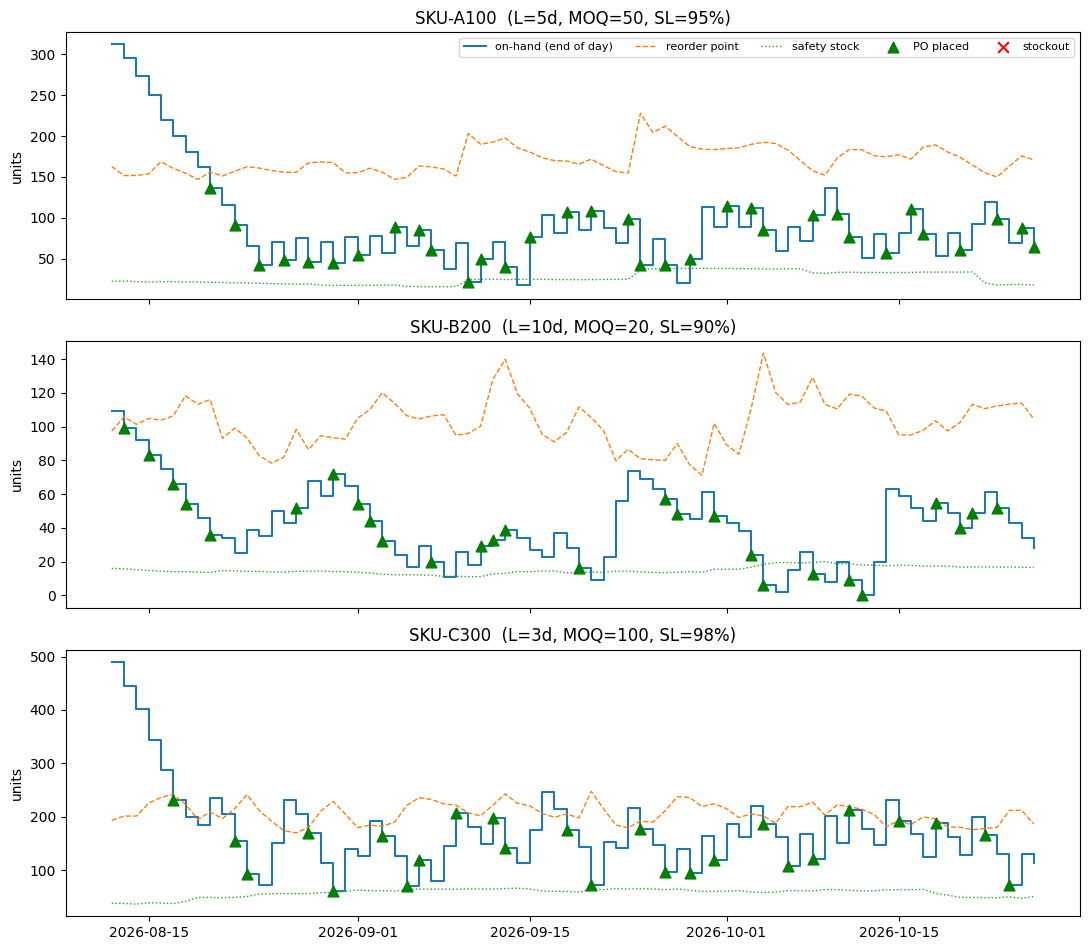

In [11]:
fig, axes = plt.subplots(len(SKUS), 1, figsize=(11, 3.2*len(SKUS)), sharex=True)
for ax, sku in zip(np.atleast_1d(axes), SKUS):
    g = log[log.sku == sku]
    ax.step(g.date, g.oh_end, where='post', label='on-hand (end of day)', lw=1.5)
    ax.plot(g.date, g.rop, ls='--', lw=1, label='reorder point')
    ax.plot(g.date, g.ss, ls=':', lw=1, label='safety stock')
    o = g[g.action == 'ORDER']; ax.scatter(o.date, o.oh_end, marker='^', s=60, c='green', label='PO placed', zorder=3)
    s = g[g.lost > 0];          ax.scatter(s.date, np.zeros(len(s)), marker='x', s=60, c='red', label='stockout', zorder=3)
    ax.set_title(f'{sku}  (L={load_params(sku).lead_time_days}d, MOQ={load_params(sku).min_order_qty}, '
                 f'SL={load_params(sku).service_level:.0%})'); ax.set_ylabel('units')
axes[0].legend(ncol=5, fontsize=8, loc='upper right'); plt.tight_layout(); plt.show()

## Compare policies — EWMA agent vs naive agent vs static (s,Q) from the starter

In [12]:
results = {}
for pol in ['EWMA', 'Naive', 'Static (s,Q)']:
    _, k = run_simulation(pol)
    results[pol] = k.loc['TOTAL']
cmp = pd.DataFrame(results).T[['fill_rate','stockout_days','lost','POs','avg_on_hand',
                               'holding_cost','stockout_cost','order_cost','total_cost']]
display(cmp.style.format({**fmt, 'stockout_days': '{:.0f}', 'lost': '{:.0f}', 'POs': '{:.0f}'}))

per_sku = pd.concat({pol: run_simulation(pol)[1].drop('TOTAL')[['fill_rate','total_cost']] for pol in results}, axis=1)
display(per_sku.style.format('{:.3f}'))

,fill_rate,stockout_days,lost,POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost
EWMA,100.0%,0,0,85,306.8,$191.68,$0.00,$0.00,$191.68
Naive,100.0%,0,0,69,372.1,$261.67,$0.00,$0.00,$261.67
"Static (s,Q)",100.0%,0,0,43,278.5,$240.31,$0.00,$0.00,$240.31


### Stress test — demand surge
With the base data every policy hits ~100% fill rate, so here demand jumps **+60% for the last 30 days** (think: viral product / holiday rush). This shows which policy *adapts*.

In [13]:
SURGE, SURGE_DAYS = 1.6, 30
shock = demand.copy()
shock.iloc[-SURGE_DAYS:] = (shock.iloc[-SURGE_DAYS:] * SURGE).round().astype(int)

stress = {pol: run_simulation(pol, demand_df=shock)[1].loc['TOTAL'] for pol in ['EWMA', 'Naive', 'Static (s,Q)']}
stress_cmp = pd.DataFrame(stress).T[['fill_rate','stockout_days','lost','POs','avg_on_hand',
                                     'holding_cost','stockout_cost','total_cost']]
display(stress_cmp.style.format({**fmt, 'stockout_days': '{:.0f}', 'lost': '{:.0f}', 'POs': '{:.0f}'}))

log_shock, _ = run_simulation('EWMA', demand_df=shock)
print('Agent decisions on stockout days during the surge (EWMA):')
print_agent_log(log_shock[log_shock.lost > 0])

,fill_rate,stockout_days,lost,POs,avg_on_hand,holding_cost,stockout_cost,total_cost
EWMA,99.2%,5,50,106,320.2,$203.77,"$1,125.00","$1,328.77"
Naive,99.8%,2,14,79,394.1,$290.01,$315.00,$605.01
"Static (s,Q)",94.2%,21,375,50,233.1,$203.45,"$2,200.74","$2,404.19"


Agent decisions on stockout days during the surge (EWMA):

=================== SKU-B200 ===================
2026-10-03 | OH   16           ->    0 | dem  22 sold  16 | ORDER   51 | IP 116 < ROP 166 (fcst 13.1/d x 11d + SS 22); projected stockout in 1d. Order 51 (need 51), arrives 2026-10-13. ALERT: even with POs already on order, shortage projected in 1d but this PO needs 10d -> consider expediting.  ** STOCKOUT: lost 6
2026-10-04 | OH    0           ->    0 | dem  29 sold   0 | ORDER   55 | IP 167 < ROP 222 (fcst 17.9/d x 11d + SS 25); projected stockout in 1d. Order 55 (need 55), arrives 2026-10-14. ALERT: even with POs already on order, shortage projected in 1d but this PO needs 10d -> consider expediting.  ** STOCKOUT: lost 29
2026-10-05 | OH    0           ->    0 | dem   6 sold   0 | WAIT       | IP 222 >= ROP 185; 0.0d of cover, projected stockout in 4d. Waiting avoids ~$1.15/day extra holding cost.  ** STOCKOUT: lost 6
2026-10-08 | OH   20           ->    0 | dem  21 sold  20 |

### Sensitivity — what does a higher service level cost?
Same EWMA agent on the surge scenario, every SKU forced to one service level.

,fill_rate,holding_cost,stockout_cost,total_cost
service_level,,,,
0.800000,98.8%,$177.08,"$1,366.33","$1,543.41"
0.850000,98.9%,$183.87,"$1,257.58","$1,441.45"
0.900000,99.0%,$195.43,"$1,155.08","$1,350.50"
0.950000,99.3%,$205.65,"$1,035.00","$1,240.65"
0.980000,99.4%,$220.70,$922.50,"$1,143.20"
0.990000,99.4%,$229.55,$855.00,"$1,084.55"


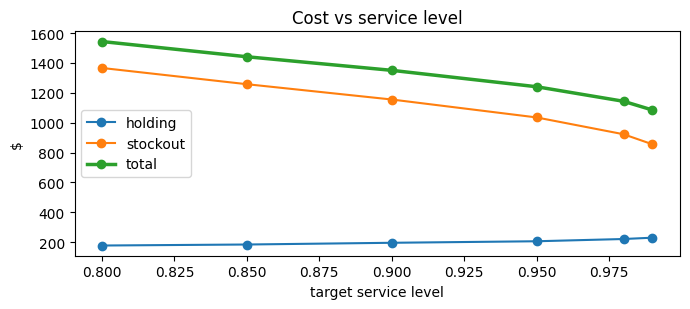

In [14]:
sl_rows = []
for sl in [0.80, 0.85, 0.90, 0.95, 0.98, 0.99]:
    k = run_simulation('EWMA', service_level=sl, demand_df=shock)[1].loc['TOTAL']
    sl_rows.append({'service_level': sl, 'fill_rate': k.fill_rate, 'holding_cost': k.holding_cost,
                    'stockout_cost': k.stockout_cost, 'total_cost': k.total_cost})
sl_df = pd.DataFrame(sl_rows).set_index('service_level')
display(sl_df.style.format({'fill_rate': '{:.1%}', 'holding_cost': '${:,.2f}', 'stockout_cost': '${:,.2f}', 'total_cost': '${:,.2f}'}))

fig, ax = plt.subplots(figsize=(7,3.2))
ax.plot(sl_df.index, sl_df.holding_cost, marker='o', label='holding')
ax.plot(sl_df.index, sl_df.stockout_cost, marker='o', label='stockout')
ax.plot(sl_df.index, sl_df.total_cost, marker='o', lw=2.5, label='total')
ax.set_xlabel('target service level'); ax.set_ylabel('$'); ax.set_title('Cost vs service level'); ax.legend()
plt.tight_layout(); plt.show()

## Findings
*(Numbers from the default data: seed 42, 3 SKUs, 76 simulated days. They will change if you regenerate the data.)*

**Base case**
- The EWMA agent hit a **100% fill rate with zero stockouts** at a total cost of **~\$192**. That is 27% cheaper than the naive agent (~\$262) and 20% cheaper than the static (s,Q) policy (\~\$240).
- EWMA forecasts beat naive on every SKU (MAE 4.2 vs 5.3 on A100). Smoother forecasts give a smaller σ, which means less safety stock and lower holding cost.
- The static (s,Q) policy is actually the cheapest on A100 and C300, because their demand barely changes. Its weak spot is **B200**, the slow SKU with a 10-day lead time: it carries too much stock there and costs ~\$162 vs ~\$97 for the agent.

**Demand surge (+60% for the last 30 days)**
- The static policy breaks down: **94.2% fill rate, 375 units lost, ~\$2,404 total cost**. Its fixed reorder point never adapts.
- The EWMA agent holds a **99.2%** fill rate. Naive does even better (**99.8%**) because "tomorrow = today" reacts to a jump instantly, while EWMA (α = 0.3) takes a few days to catch up.
- **Every stockout is on SKU-B200**, the SKU with a 10-day lead time. The agent raised an **ALERT** to expedite before each one. No reorder rule can fix a stockout that falls inside the lead time, so the real fix is expediting or a closer supplier.
- **Raising the service level pays off when demand is volatile:** going from 0.80 to 0.99 adds ~\$52 of holding cost but saves ~\$511 in stockout cost.

**Known limitations / next steps**
- The agent waits whenever inventory position ≥ ROP, even when a shortage is projected before the next arrival (see the B200 rows on 10/05). It could also check *timing*, not just total quantity.
- Possible extensions: tune α per SKU (or let the agent switch to a faster α when errors spike); add a fixed PO cost (`ORDER_COST_FIXED`) so EOQ batching kicks in; model lead-time variability.

In [15]:
log.to_csv('agent_log.csv', index=False)
kpi.to_csv('agent_kpis.csv')
print('Saved agent_log.csv and agent_kpis.csv')

Saved agent_log.csv and agent_kpis.csv
